# Util functions

In [94]:
import numpy as np

def create_results_dict(
        input
    ):
    """ Returns results as a dictionary, to make it easier to compare between runs. """

    nt, dt, time_array, T_parcel_array, P_parcel_array, RH_parcel_array, q_parcel_array, z_parcel_array, \
    qa_ts, qc_ts, qr_ts, na_ts, nc_ts, nr_ts, \
    spectra_arr, con_ts, act_ts, evp_ts, dea_ts, acc_ts, aut_ts, precip_ts, particles_array, \
    rc_liq_avg_array, rc_liq_std_array, r_liq_avg_array, r_liq_std_array, \
    particles_c_array, \
    TAU_ts_array, albedo_array = input

    results = {
        'nt': nt, 'dt': dt, 'time': time_array, 'T_parcel': T_parcel_array, 'P_parcel': P_parcel_array, 'RH_parcel': RH_parcel_array, 'q_parcel': q_parcel_array, 'z_parcel': z_parcel_array,
        'qa': qa_ts, 'qc': qc_ts, 'qr': qr_ts, 'na': na_ts, 'nc': nc_ts, 'nr': nr_ts,
        'spectra': spectra_arr, 'con': con_ts, 'act': act_ts, 'evp': evp_ts, 'dea': dea_ts, 'acc': acc_ts, 'aut': aut_ts, 'precip': precip_ts, 'particles': particles_array,
        'rc_liq_avg': rc_liq_avg_array, 'rc_liq_std': rc_liq_std_array, 'r_liq_avg': r_liq_avg_array, 'r_liq_std': r_liq_std_array,
        'particles_c_array': particles_c_array,
        'tau': TAU_ts_array, 'albedo': albedo_array
    }
    
    return results


def extract_widget_inputs(
    dt_widget, nt_widget, Condensation_widget, Collision_widget, switch_sedi_removal_widget, n_particles_widget, max_z_widget,
    T_widget, P_widget, RH_widget, w_widget, z_widget, ascending_mode_widget,
    entrainment_widget, entrainment_start_widget, entrainment_duration_widget, entrainment_rate_widget, rh_env_widget, mixing_degree_widget,
    kohler_widget, hygroscopicity_widget, mode_aero_init_widget, gridwidget, preset_widget,
    kelvin_widget, solute_widget, E_const_widget, vt_simple_widget, turb_kernel_widget, epsilon_widget, adaptive_dt_widget, switch_breakup_widget,
    mode_displaytype_widget
    ):

    """ Convert widget input parameters to raw values to input to model. """
    
    # Model steering parameters
    dt = dt_widget.value
    nt = nt_widget.value

    do_condensation = Condensation_widget.value
    do_collision    = Collision_widget.value

    n_particles = n_particles_widget.value

    # Parcel initial parameters
    T_parcel   = T_widget.value
    P_parcel   = P_widget.value
    RH_parcel  = RH_widget.value
    w_parcel   = w_widget.value
    z_parcel   = z_widget.value

    max_z = max_z_widget.value

    ascending_mode  = ascending_mode_widget.value

    display_mode    = mode_displaytype_widget.value
    
    # Aerosol initialization
    mode_aero_init = mode_aero_init_widget.value

    # Read in the variables given above taking into account unit factors
    N_aero      = [gridwidget[1, 0].value*1.0E6, gridwidget[1, 1].value*1.0E6, gridwidget[1, 2].value*1.0E6, gridwidget[1, 3].value*1.0E6]
    mu_aero     = [gridwidget[2, 0].value*1.0E-6, gridwidget[2, 1].value*1.0E-6, gridwidget[2, 2].value*1.0E-6, gridwidget[2, 3].value*1.0E-6]
    sigma_aero  = [gridwidget[3, 0].value, gridwidget[3, 1].value, gridwidget[3, 2].value, gridwidget[3, 3].value]
    k_aero      = [gridwidget[4, 0].value, gridwidget[4, 1].value, gridwidget[4, 2].value, gridwidget[4, 3].value]

    preset_widget.value

    kohler_activation_radius    = kohler_widget.value
    switch_kappa_koehler        = hygroscopicity_widget.value
    switch_sedi_removal         = switch_sedi_removal_widget.value
    entrainment_rate            = entrainment_rate_widget.value
    switch_entrainment          = entrainment_widget.value
    entrainment_start           = entrainment_start_widget.value
    entrainment_duration        = entrainment_duration_widget.value

    entrainment_end = entrainment_start + entrainment_duration

    # stability_widget.value
    rh_env = rh_env_widget.value
    ihmd = mixing_degree_widget.value

    # Ablation lab
    switch_kelvin = kelvin_widget.value
    switch_solute = solute_widget.value
    switch_E_constant = E_const_widget.value
    switch_vt_simple = vt_simple_widget.value
    switch_turb_kernel = turb_kernel_widget.value
    epsilon_turb = epsilon_widget.value
    switch_adaptive_dt = adaptive_dt_widget.value
    switch_breakup = switch_breakup_widget.value

    # theta_profiles

    return \
        dt, nt, do_condensation, do_collision, n_particles, \
        T_parcel, P_parcel, RH_parcel, w_parcel, z_parcel, max_z, \
        ascending_mode, display_mode, \
        mode_aero_init, N_aero, mu_aero, sigma_aero, k_aero, \
        kohler_activation_radius, switch_kappa_koehler, switch_sedi_removal, \
        entrainment_rate, switch_entrainment, entrainment_start, entrainment_end, \
        rh_env, ihmd, \
        switch_kelvin, switch_solute, switch_E_constant, switch_vt_simple, switch_turb_kernel, epsilon_turb, switch_adaptive_dt, switch_breakup

# Setup model

In [95]:
# Import necessary modules
from droplab.animation import *
from droplab.widget import *
from droplab.timestep_routine import *
from droplab.parameters import *
# Import user modifiable modules
from Post_process.analysis import *
from Post_process.print_plot import *

# Uncomment lines below when changing source files
#######################
%load_ext autoreload
%autoreload 2
#######################

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## User interface (initialise model with widgets)

You can use the user interface widgets below to initialise the model, if you find it more intuitive than the direct input.

### Model steering parameters

In [96]:
dt_widget, nt_widget, Condensation_widget, Collision_widget, switch_sedi_removal_widget, n_particles_widget, max_z_widget = model_steering_input()

'Model steering parameters'

BoundedFloatText(value=1.0, description='dt (s):', max=5.0, min=0.0001, style=DescriptionStyle(description_wid…

BoundedIntText(value=3600, description='nt:', max=100000, min=1, style=DescriptionStyle(description_width='ini…

Checkbox(value=True, description='Condensation', style=CheckboxStyle(description_width='initial'))

Checkbox(value=False, description='Collision', style=CheckboxStyle(description_width='initial'))

BoundedIntText(value=1000, description='n_particles:', max=10000, min=100, style=DescriptionStyle(description_…

BoundedFloatText(value=3000.0, description='z_max (m):', max=10000.0, step=0.1, style=DescriptionStyle(descrip…

### Parcel parameters

In [97]:
T_widget, P_widget, RH_widget, w_widget, z_widget = parcel_info_input()

ascending_mode_widget = ascending_mode_input()

'Parcel initial parameters: '

BoundedFloatText(value=293.2, description='T (K):', max=320.0, min=200.0, step=0.1, style=DescriptionStyle(des…

BoundedFloatText(value=101300.0, description='P (Pa):', max=105000.0, min=95000.0, step=1.0, style=Description…

BoundedFloatText(value=0.88, description='RH (-):', max=2.0, min=0.01, step=0.01, style=DescriptionStyle(descr…

BoundedFloatText(value=1.0, description='w (m/s):', max=10.0, step=0.1, style=DescriptionStyle(description_wid…

BoundedFloatText(value=0.0, description='z (m):', max=20000.0, step=100.0, style=DescriptionStyle(description_…

ToggleButtons(description='Mode', layout=Layout(width='max-content'), options=('linear', 'sine', 'in_cloud_osc…

### Entrainment parameters

In [98]:
entrainment_widget, stability_widget, entrainment_start_widget, entrainment_duration_widget, entrainment_rate_widget, rh_env_widget, mixing_degree_widget = entrainment_input()

'Entrainment parameters: '

Checkbox(value=False, description='Entrainment', style=CheckboxStyle(description_width='initial'))

ToggleButtons(description='Stability', layout=Layout(width='max-content'), options=('Stable', 'Unstable', 'Neu…

IntText(value=600, description='Entrainment start time (s)', style=DescriptionStyle(description_width='initial…

IntText(value=600, description='Entrainment duration (s)', style=DescriptionStyle(description_width='initial')…

FloatText(value=0.001, description='Fractional entrainment rate ($ \\mathrm{m}^{-1} $)', layout=Layout(width='…

FloatSlider(value=0.2, description='Environment RH', layout=Layout(width='max-content'), max=1.0, step=0.05, s…

FloatSlider(value=0.0, description='IHMD', layout=Layout(width='max-content'), max=1.0, step=0.05, style=Slide…

#### Environment (used only when entrainment is enabled)

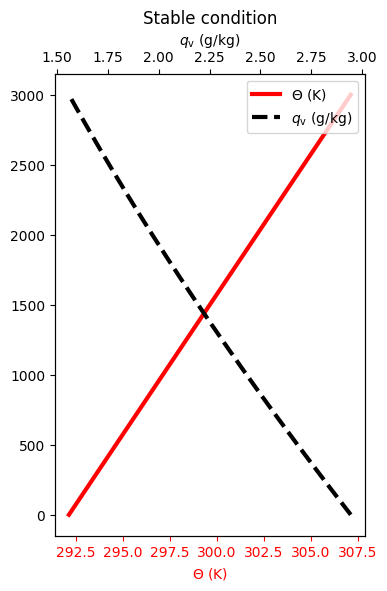

Entrainment (if enabled): lambda=0.001/m for 600s at w=1 m/s -> ~45% of the parcel replaced by 20%-RH environment air


In [99]:
# Draw the environmental sounding (potential temperature from stability + moisture at the chosen
# Environment RH). `theta_profiles` also sets the hydrostatic pressure during ascent; the
# entrainment moisture is computed inline from the RH, not read from this array.
_qv_env, theta_profiles, z_env = create_env_profiles(T_widget.value, 0.0, z_widget.value,
                                                     P_widget.value, stability_widget.value,
                                                     rh_env_widget.value)

# Entrainment strength readout: turn the per-metre rate into the actual fraction mixed in.
from droplab.mixing import entrained_fraction
_ef = entrained_fraction(entrainment_rate_widget.value, w_widget.value, dt_widget.value, entrainment_duration_widget.value)
print(f"Entrainment (if enabled): lambda={entrainment_rate_widget.value:g}/m for "
      f"{entrainment_duration_widget.value:g}s at w={w_widget.value:g} m/s -> ~{_ef*100:.0f}% of the parcel "
      f"replaced by {rh_env_widget.value*100:.0f}%-RH environment air")

### Aerosol parameters

In [100]:
#Use activation radius with Koehler critical radius
kohler_widget = kohler_settings()
#Use hygroscopicity parameter, otherwise, sea-salt aerosols are initialized 
hygroscopicity_widget = kappa_settings()
#Choose the mode for aerosol initialization
mode_aero_init_widget = aero_mode_input()
# Initialization parameters for aerosol (up to 4 modes)
gridwidget = grid_modes_input()

'Set activation radius using Koehler critical radius, otherwise activation radius is 1 µm'

Checkbox(value=False, description='Koehler critical radius', layout=Layout(width='max-content'), style=Checkbo…

'Use hygroscopicity parameter from kappa-kohler theory'

Checkbox(value=False, description='Hygroscopicity', layout=Layout(width='max-content'), style=CheckboxStyle(de…

'Aerosol initialisation mode: '

ToggleButtons(layout=Layout(width='max-content'), options=('Random', 'Weighting_factor'), value='Random')

N_aero: number of aerosols per cubic centimeter, mu: mean droplet radius, sigma: std of mu


GridspecLayout(children=(Button(button_style='info', description='Mode #1', layout=Layout(grid_area='widget001…

In [101]:
# Load a preset aerosol configuration (Maritime, Continental, Arctic) or keep Custom values
preset_widget = preset_input(gridwidget)

Dropdown(description='Aerosol preset:', options=('Custom', 'Maritime', 'Continental', 'Arctic'), style=Descrip…

### Ablation Lab

In [102]:
kelvin_widget, solute_widget, E_const_widget, vt_simple_widget, turb_kernel_widget, epsilon_widget, adaptive_dt_widget, switch_breakup_widget = ablation_settings()

'Ablation Lab - Physics toggles:'

Checkbox(value=True, description='Curvature (Kelvin) effect', style=CheckboxStyle(description_width='initial')…

Checkbox(value=True, description='Solute (Raoult) effect', style=CheckboxStyle(description_width='initial'))

Checkbox(value=False, description='Constant collision efficiency (E=1)', style=CheckboxStyle(description_width…

Checkbox(value=False, description='Simplified terminal velocity (Stokes)', style=CheckboxStyle(description_wid…

Checkbox(value=False, description='Turbulent collision kernel (Wang-Ayala)', style=CheckboxStyle(description_w…

BoundedFloatText(value=0.01, description='TKE dissipation rate ε (m²/s³):', max=0.1, step=0.001, style=Descrip…

Checkbox(value=False, description='Adaptive condensation substep (Arnason & Brown 1971)', style=CheckboxStyle(…

Checkbox(value=False, description='Collisional breakup (Straub 2010)', layout=Layout(width='max-content'), sty…

# Time step routine

In [103]:
# setting of display mode while running: either output of variables in text form (fast, recommended) = 'text_fast'
# or: continuously updated plot using plotly (slow, time & memory consuming) = 'graphics'
mode_displaytype_widget = timestep_display_mode_settings()

'Display mode: '

ToggleButtons(layout=Layout(width='max-content'), options=('text_fast', 'graphics'), value='text_fast')

## Extract widget inputs

In [104]:
dt, nt, do_condensation, do_collision, n_particles, \
T_parcel, P_parcel, RH_parcel, w_parcel, z_parcel, max_z, \
ascending_mode, display_mode, \
mode_aero_init, N_aero, mu_aero, sigma_aero, k_aero, \
kohler_activation_radius, switch_kappa_koehler, switch_sedi_removal, \
entrainment_rate, switch_entrainment, entrainment_start, entrainment_end, \
rh_env, ihmd, \
switch_kelvin, switch_solute, switch_E_constant, switch_vt_simple, switch_turb_kernel, epsilon_turb, switch_adaptive_dt, switch_breakup = \
    extract_widget_inputs(
        dt_widget, nt_widget, Condensation_widget, Collision_widget, switch_sedi_removal_widget, n_particles_widget, max_z_widget,
        T_widget, P_widget, RH_widget, w_widget, z_widget, ascending_mode_widget,
        entrainment_widget, entrainment_start_widget, entrainment_duration_widget, entrainment_rate_widget, rh_env_widget, mixing_degree_widget,
        kohler_widget, hygroscopicity_widget, mode_aero_init_widget, gridwidget, preset_widget,
        kelvin_widget, solute_widget, E_const_widget, vt_simple_widget, turb_kernel_widget, epsilon_widget, adaptive_dt_widget, switch_breakup_widget,
        mode_displaytype_widget
    )

## Direct input (without widgets)

You can directly assign parameters in the code below rather than using the widgets. This can be more convenient as the widgets will override your original input when reloaded.

If you prefer to use the widget UI above, **do not run the code block directly below this one**. Instead, skip to 'Run model'.

In [105]:
%%capture
# ^ Don't show entrainment plot

# rm_spec is imported from parameters module

# Model steering parameters

dt                  = 1 # s
nt                  = 4500
do_condensation     = True
do_collision        = True
switch_sedi_removal = False
n_particles         = 500 # -
max_z               = 5000 # m


# Parcel initial parameters

T_parcel        = 289.27 # K
P_parcel        = 101181 # Pa
RH_parcel       = 0.83
w_parcel        = 0.3 # m s-1
z_parcel        = 0 # m
ascending_mode  = 'linear' # linear / sine / in_cloud_oscillation


# Entrainment parameters

switch_entrainment  = False
stability           = 'Stable' # Stable / Unstable / Neutral
# entrainment_start   = 1000 # s
# entrainment_duration = 30 # s
# entrainment_end     = entrainment_start + entrainment_end
# entrainment_rate    = 0.05
# rh_env = 0.20
# ihmd = 0

# Even if you are not using entrainment, you need to calculate these
qv_init = RH_parcel * esatw( T_parcel ) / ( P_parcel - RH_parcel * esatw( T_widget.value ) ) * r_a / rv
_qv_env, theta_profiles, z_env = create_env_profiles(T_parcel, qv_init, z_parcel, P_parcel, stability, rh_env)


# Koehler theory

kohler_activation_radius    = False
switch_kappa_koehler        = True
mode_aero_init              = 'Random' # Random / Weighting_factor


# Initialisation parameters for aerosol (up to 4 modes)
# N_aero = number of aerosol per cm3 of air | mu = mean droplet radius | sigma = std. of mu | kappa = hygroscopicity parameter

# Mode #1
N_aero[0]       = 11.7e6 # N_aero (m-3)
mu_aero[0]      = 9.0e-9 # mu (m)
sigma_aero[0]   = 1.416 # sigma (-)
k_aero[0]       = 1.28 # kappa

# Mode #2
N_aero[1]       = 38.4e6 # N_aero (m-3)
mu_aero[1]      = 19.5e-9 # mu (m)
sigma_aero[1]   = 1.425 # sigma (-)
k_aero[1]       = 1.28 # kappa

# Mode #3
N_aero[2]       = 41.7e6 # N_aero (m-3)
mu_aero[2]      = 77.0e-9 # mu (m)
sigma_aero[2]   = 1.592 # sigma (-)
k_aero[2]       = 1.28 # kappa

# Mode #4
N_aero[3]       = 0 # N_aero (m-3)
mu_aero[3]      = 0 # mu (m)
sigma_aero[3]   = 0 # sigma (-)
k_aero[3]       = 0 # kappa


# Ablation lab
switch_kelvin           = True # curvature (Kelvin) effect
switch_solute           = True # solute (Raoult) effect
switch_E_constant       = False # Constant collision efficiency (E=1)
switch_vt_simple        = False # Simplified terminal velocity (Stokes)
switch_turb_kernel      = False # Turbulent collision kernel (Wang-Ayala)
epsilon_turb            = 0.01 # TKE dissipation rate (m2 s-3)
switch_adaptive_dt      = False # Adaptive condensation substep
switch_breakup          = False # Collisional breakup (Straub 2010)


# Display mode

display_mode = 'text_fast' # text_fast / graphics

## Run model

In [106]:
test_run \
    = create_results_dict(timesteps_function(
        dt, nt, do_condensation, do_collision, n_particles,
        T_parcel, P_parcel, RH_parcel, w_parcel, z_parcel, max_z,
        rm_spec, ascending_mode, display_mode,
        mode_aero_init, N_aero, mu_aero, sigma_aero, k_aero,
        kohler_activation_radius, switch_kappa_koehler, switch_sedi_removal,
        entrainment_rate, switch_entrainment, entrainment_start, entrainment_end,
        rh_env, ihmd, theta_profiles,
        switch_kelvin, switch_solute, switch_E_constant, switch_vt_simple, switch_turb_kernel, epsilon_turb, switch_adaptive_dt, switch_breakup
        
    ))

LCM timesteps: 100%|██████████| 4500/4500 [00:34<00:00, 131.57step/s]

value: Time (s)  z (m)    T (K)    qv (g/kg) RH (%)   QC (g/kg) QR (g/kg) NA (/mg) NC (/mg) NR (/mg)
after: 4500.0    1350.00  280.67   7.66      100.816   0.062     1.777     19.88     4.40      0.09    


# Post Processing and Analysis

## List of Outputs

The units refer to the units used in the export output dataset in csv-format (see below). Important: If using the output directly in this notebook there are sometimes different units. These cases are explained below and have to be taken into account when performing exercises.

* `T_parcel_array`: Parcel temperature (K)
* `RH_parcel_array`: Parcel relative humidity (-)
* `q_parcel_array`: Parcel vapor mixing ratio (g/kg) (internal: kg/kg)
* `z_parcel_array`: Parcel height (m)

* `qa_ts`, `qc_ts`, `qr_ts`: Aerosol, cloud droplet, raindrop mixing ratio (g/kg)  
* `na_ts`, `nc_ts`, `nr_ts`: Aerosol, cloud droplet, raindrop number concentration (/mg) (internal: *1e6)

* `con_ts`: Condensation rate (g/kg/s)  
* `evp_ts`: Evaporation rate (g/kg/s) 

* `act_ts`: Aerosol activation rate (g/kg/s) 
* `dea_ts`: Aerosol deactivation rate (g/kg/s) 

* `aut_ts`: Autoconversion rate (g/kg/s)
* `acc_ts`: Accretion rate (g/kg/s) 

* `precip_ts`: Precipitation (g/kg)

* `spectra_arr`: Droplet size distribution (time $\times$ droplet radius bin)

Droplet-radius statistics come in two forms — over **all** droplets (haze included) and over **cloud + rain** droplets only (radius > activation radius):

* `r_liq_avg_array`, `rc_liq_avg_array`: Mean droplet radius, all vs cloud+rain (µm)
* `r_liq_std_array`, `rc_liq_std_array`: Standard deviation of droplet radius, all vs cloud+rain (µm)
* `particles_array`, `particles_c_array`: Per-timestep radius of every super-droplet (particle $i$ $\times$ time); `particles_c_array` zeroes the haze so only cloud+rain radii remain

Cloud reflectivity outputs:

* `TAU_ts_array`: Optical thickness (-) (Mitchell 2000)
* `albedo_array`: Albedo (-) (Seinfeld and Pandis 2006)

## Plots
Plots can be drawn either as time series or as vertical profiles.

In [107]:
# Choose whether plots are time-dependent or height-dependent (DSD and particle-number densities are always time-dependent)
mode_plots_widget, increment_widget, droplet_mode_widget = plot_widgets_settings(nt)

ToggleButtons(description='Plots are:', layout=Layout(width='max-content'), options=('time-series', 'vertical …

'For droplet spectra: set increment (e.g. 20: every 20th timestep a line is drawn): '

BoundedIntText(value=20, description='For droplet spectra: increment: ', max=4500, min=1, style=DescriptionSty…

ToggleButtons(description='Show only:', index=2, layout=Layout(width='max-content'), options=('Aerosol mode', …

In [108]:
plot_run = test_run

/Users/zrowland/Desktop/repos/DropLab_branches/DropLab/Post_process/print_plot.py:26: UserWarning: Log scale: values of z <= 0 have been masked
  contour = ax.contourf(np.arange(nt+1)*dt, 1e6*rm_spec, spectra_arr.T, norm=matplotlib.colors.LogNorm())


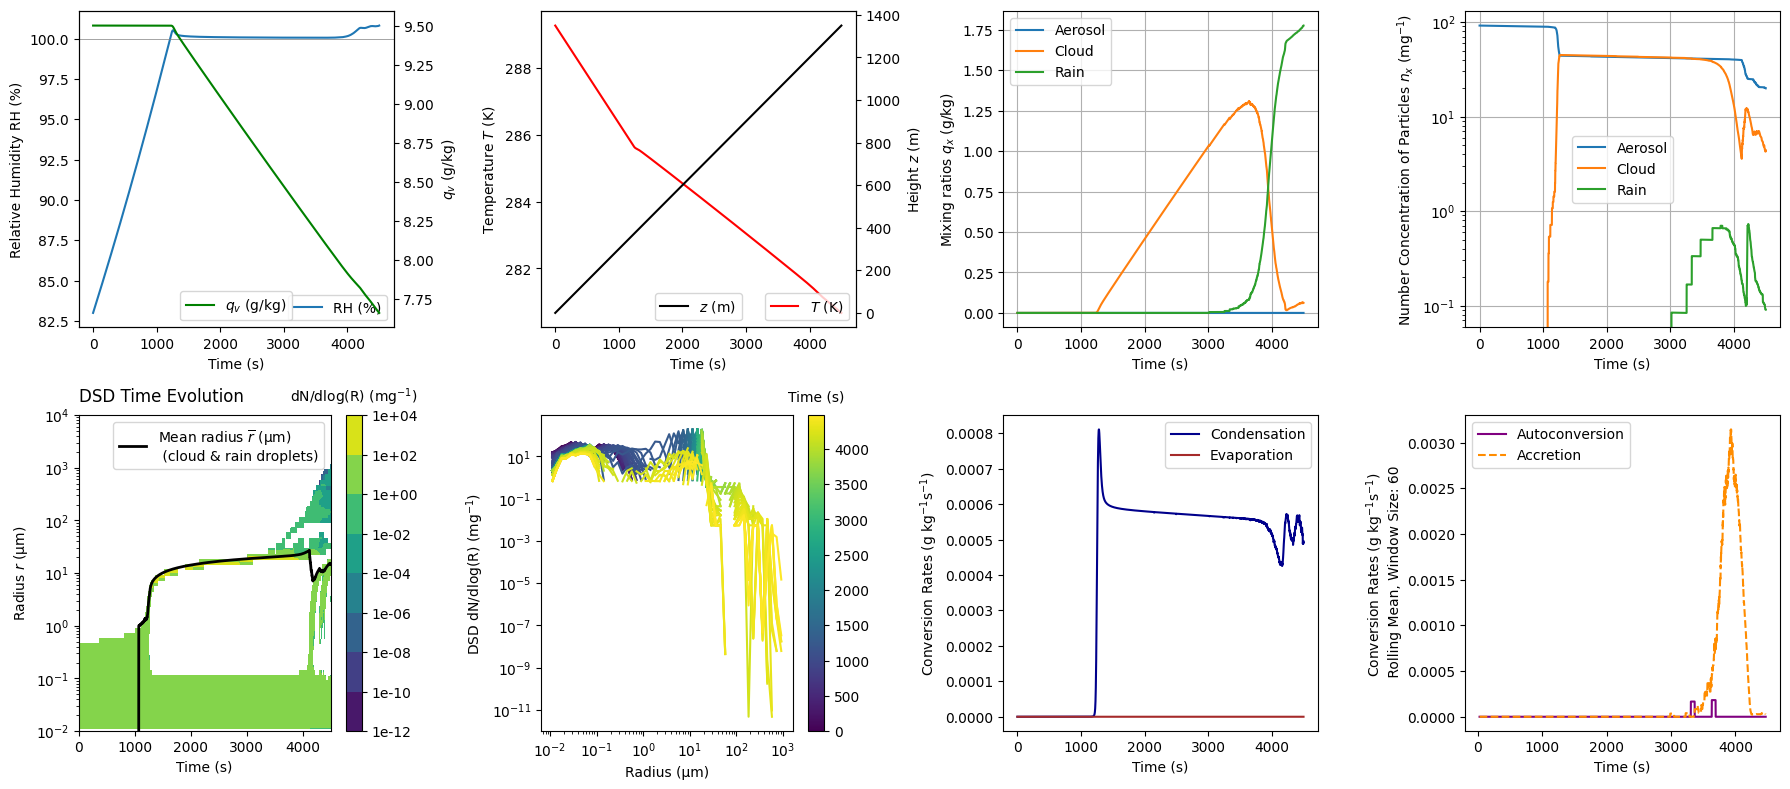

In [109]:
plot_mode = mode_plots_widget.value

subplot_array_function(
    plot_mode, dt, nt, rm_spec,
    plot_run['qa'], plot_run['qc'], plot_run['qr'],
    plot_run['na'], plot_run['nc'], plot_run['nr'],
    plot_run['T_parcel'], plot_run['RH_parcel'], plot_run['q_parcel'], plot_run['z_parcel'],
    plot_run['spectra'], increment_widget, plot_run['con'], plot_run['act'], plot_run['evp'],
    plot_run['dea'], plot_run['acc'], plot_run['aut'], plot_run['rc_liq_avg'],
    droplet_mode_widget.value
)

In [110]:
# Align z to cloud base, assuming cloud base where supersaturation = 0
cb_idx = np.abs(plot_run['RH_parcel']-1).argmin()
z_array = plot_run['z_parcel'] - plot_run['z_parcel'][cb_idx]

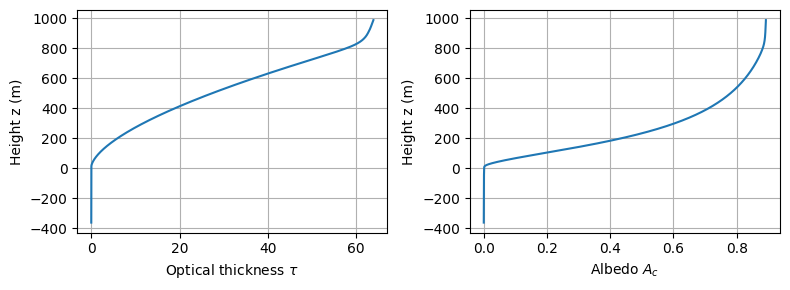

In [111]:
# Tau, albedo plots

fig, ax = plt.subplots(1, 2, figsize=(8,3))

ax[0].plot(plot_run['tau'], z_array)
ax[1].plot(plot_run['albedo'], z_array)

ax[0].set_ylabel('Height z (m)')
ax[1].set_ylabel('Height z (m)')

ax[0].set_xlabel('Optical thickness $τ$')
ax[1].set_xlabel('Albedo $A_c$')

ax[0].grid(); ax[1].grid()

plt.tight_layout()
plt.show()

/var/folders/pm/yr9p5vts11g53s85rr_h4kw8tlv16r/T/ipykernel_34447/658544974.py:14: UserWarning: Log scale: values of z <= 0 have been masked
  contour = ax.contourf(
/var/folders/pm/yr9p5vts11g53s85rr_h4kw8tlv16r/T/ipykernel_34447/658544974.py:25: UserWarning: Attempt to set non-positive xlim on a log-scaled axis will be ignored.
  ax.set_xlim([0,2e2])


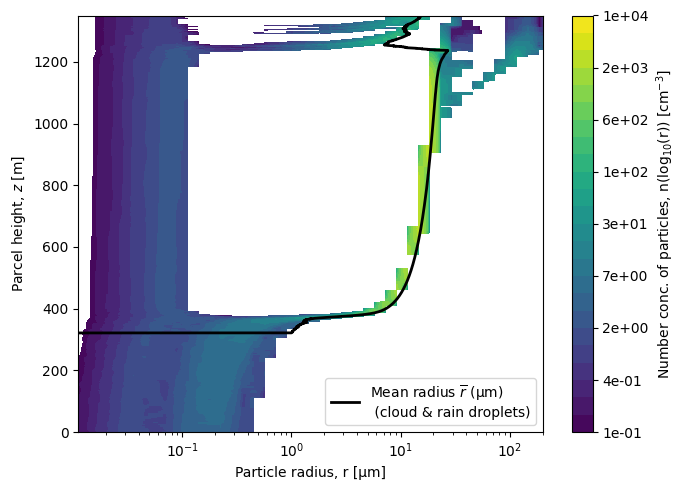

In [112]:
# Customisable DSD plot
# The bin resolution of the plot can be increased by making the parameter 'alpha_spec' in parameters.py smaller (default value 1.0).
# This may lead to a plot with more 'gaps' due to smaller bins. This can be remedied by increasing the number of computational particles ('n_particles') above.

import math

fig, ax = plt.subplots(figsize=(7,5))

z_array = plot_run['z_parcel']
spectra_array = plot_run['spectra'] * rm_spec
levels = np.logspace(-1, math.floor(math.log10(spectra_array.max()))+1, 25)

# Create the contour plot with a logarithmic color scale
contour = ax.contourf(
    rm_spec*1e6, z_array, spectra_array,
    norm=matplotlib.colors.LogNorm(vmin=levels.min(), vmax=levels.max()), cmap='viridis', levels=levels)

fig.colorbar(contour, ax=ax, format="%.0e", label="Number conc. of particles, n(log$_{10}$(r)) [cm$^{-3}$]")

ax.plot(plot_run['rc_liq_avg']*1e6, plot_run['z_parcel'], color='black', linewidth=2, label=r'Mean radius $\overline{r}$ (µm)' + '\n (cloud & rain droplets)')

ax.set_xscale('log')
ax.set_xlabel("Particle radius, r [µm]")
ax.set_ylabel("Parcel height, $z$ [m]")
ax.set_xlim([0,2e2])
# ax.set_ylim([0,800])

ax.legend(loc='lower right')

fig.tight_layout()